# 05 — Modelo 1: regresión logística

**Elaborado por:** Santiago Cardozo

## Objetivo

Entrenar el primer modelo, una **regresión logística**, con las 11 variables seleccionadas, y
medirlo en datos que no vio (validación, 2025). Es el modelo más simple de los tres, así que
este cuadernillo también deja resueltas dos cosas que usan los demás:

1. **cómo se mide un modelo** (exactitud, ROC-AUC y log loss);
2. **con qué mapas conviene entrenar**, porque el primer intento descubre un problema.

El conjunto de prueba (2026) no se toca en este cuadernillo.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from src.config import CONFIG_PATH, PROCESSED_DIR, TABLES_DIR, load_config
from src.evaluation import accuracy_interval, evaluate, temporal_split
from src.plotting import set_style, save_fig

set_style()
config = load_config()
FEATURES, TARGET = config["features"], config["target"]

dataset = pd.read_csv(PROCESSED_DIR / "dataset.csv")
train, val, test = temporal_split(dataset, config["split"])
X_val, y_val = val[FEATURES], val[TARGET]
print(f"Entrenamiento: {len(train)} mapas | Validación: {len(val)} mapas | Variables: {len(FEATURES)}")

Entrenamiento: 25210 mapas | Validación: 1272 mapas | Variables: 11


## 1. Cómo se mide un modelo

Se usan tres métricas, porque cada una responde una pregunta distinta:

- **Exactitud (*accuracy*):** ¿en qué proporción de mapas acierta el ganador? Es la más fácil de interpretar.
- **ROC-AUC:** ¿qué tan bien *ordena* los mapas de menos a más favorables para Team A? 0.5 es azar; 1.0 es perfecto.
- **Log loss:** ¿qué tan buenas son las *probabilidades*? Castiga mucho al modelo que se
  equivoca estando muy seguro. **Menor es mejor.**

El log loss es el criterio principal de este proyecto. En un problema con tanto azar como
este, lo útil de un modelo no es decir "gana A", sino decir "A tiene 62 % de probabilidad" y
que eso sea cierto.

### ¿Cómo se calcula el log loss?

A cada predicción se le pone una penalización: **−log(probabilidad que el modelo le dio a lo
que realmente pasó)**. El log loss es el promedio de esas penalizaciones. Un ejemplo con tres mapas:

In [2]:
ejemplo = pd.DataFrame({"gano_team_a": [1, 1, 0], "prob_predicha_team_a": [0.9, 0.6, 0.8]})
prob_de_lo_que_paso = np.where(ejemplo["gano_team_a"] == 1,
                               ejemplo["prob_predicha_team_a"], 1 - ejemplo["prob_predicha_team_a"])
ejemplo["penalizacion"] = -np.log(prob_de_lo_que_paso)
print(ejemplo.round(3).to_string(index=False))
print(f"\nLog loss (promedio de las penalizaciones): {ejemplo['penalizacion'].mean():.3f}")
print(f"Penalización de responder siempre 50 %:    {-np.log(0.5):.3f}")

 gano_team_a  prob_predicha_team_a  penalizacion
           1                   0.9         0.105
           1                   0.6         0.511
           0                   0.8         1.609

Log loss (promedio de las penalizaciones): 0.742
Penalización de responder siempre 50 %:    0.693


El tercer mapa (el modelo dijo "80 % gana A" y ganó B) pesa más que los otros dos juntos:
equivocarse estando seguro sale caro. Y hay una referencia que se usará todo el tiempo:
responder siempre "50 %" da **0.693**. Un log loss mayor que 0.693 es peor que no saber nada.

Las tres métricas se calculan con `evaluate()` de `src/evaluation.py`.

## 2. Primer intento y un problema: el modelo se pasa de confiado

Se entrena una regresión logística con las 11 variables y **todo** el conjunto de entrenamiento.

Como la logística no admite valores faltantes, se rellenan con la mediana y se agrega, por
cada variable, un indicador de "este dato faltaba" (`add_indicator=True`), para que el modelo
pueda distinguir un valor real de uno rellenado. Las variables se estandarizan porque están
en escalas muy distintas.

In [3]:
def make_logistic():
    return make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
                         LogisticRegression(max_iter=2000))

first_try = make_logistic().fit(train[FEATURES], train[TARGET])
first_proba = first_try.predict_proba(X_val)[:, 1]
pd.Series(evaluate(y_val, first_proba)).round(4)

accuracy    0.5668
roc_auc     0.5899
log_loss    0.8406
dtype: float64

Exactitud y AUC normales, pero un log loss de 0.84: mucho peor que no saber nada. Se miran
las probabilidades que entrega.

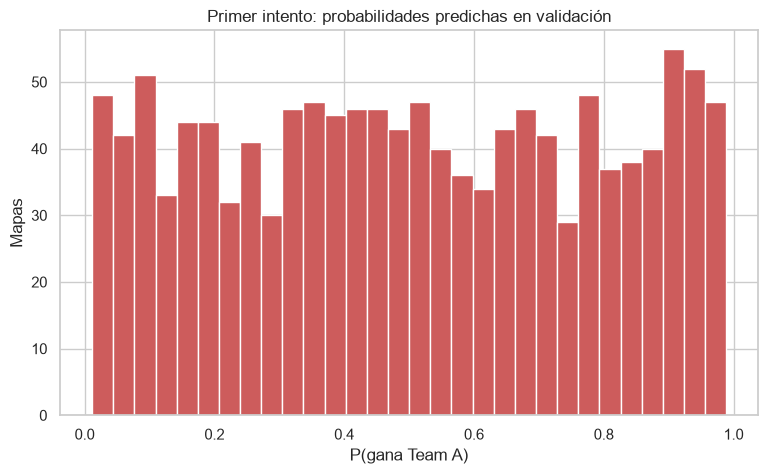

,mapas,prob_media,gano_team_a
prob,,,
"(0.0, 0.1]",125,0.06,0.43
"(0.1, 0.3]",236,0.20,0.40
"(0.3, 0.5]",277,0.40,0.46
"(0.5, 0.7]",249,0.60,0.51
"(0.7, 0.9]",243,0.80,0.55
"(0.9, 1.0]",142,0.94,0.68


In [4]:
fig, ax = plt.subplots()
ax.hist(first_proba, bins=30, color="indianred")
ax.set(title="Primer intento: probabilidades predichas en validación", xlabel="P(gana Team A)", ylabel="Mapas")
save_fig("05_probabilidades_primer_intento")
plt.show()

check = pd.DataFrame({"prob": first_proba, "gano_team_a": y_val.to_numpy()})
(check.groupby(pd.cut(check["prob"], [0, 0.1, 0.3, 0.5, 0.7, 0.9, 1]), observed=True)
 .agg(mapas=("prob", "size"), prob_media=("prob", "mean"), gano_team_a=("gano_team_a", "mean")).round(2))

**Por qué este gráfico:** el log loss dice que las probabilidades son malas, pero no dice *cómo* son. Un histograma muestra qué probabilidades entrega el modelo y con qué frecuencia.

**Cómo se lee:** el eje horizontal es la probabilidad que el modelo le dio a Team A (0 = "seguro gana B", 1 = "seguro gana A"); la altura es cuántos mapas recibieron esa probabilidad. En un problema parejo como este se esperaría una montaña alrededor de 0.5.

**Qué muestra:** el modelo reparte probabilidades por todo el rango, desde casi 0 hasta casi 1, como si muchos partidos estuvieran decididos de antemano. La tabla de abajo lo desmiente: cuando el modelo dice "94 %" (último tramo), Team A gana solo el 68 % de las veces; cuando dice "6 %" (primer tramo), gana el 43 %. El modelo **se pasa de confiado**, y el log loss castiga justamente eso.

**¿Por qué pasa esto?** Se comparan las variables en entrenamiento y en validación.

In [5]:
shift = pd.DataFrame({
    "std_train": train[FEATURES].std(), "std_val": val[FEATURES].std(),
    "median_train": train[FEATURES].median(), "median_val": val[FEATURES].median(),
}).round(2)
print(f"Mapas con ambos equipos con 30+ mapas previos → entrenamiento: "
      f"{(train['min_maps_played'] >= 30).mean():.1%} | validación: {(val['min_maps_played'] >= 30).mean():.1%}")
shift.loc[["diff_maps_played", "min_maps_played", "diff_winrate", "diff_round_diff", "diff_acs"]]

Mapas con ambos equipos con 30+ mapas previos → entrenamiento: 20.3% | validación: 85.1%


,std_train,std_val,median_train,median_val
diff_maps_played,41.43,158.57,0.00,-2.00
min_maps_played,40.02,99.37,4.00,106.00
diff_winrate,0.24,0.16,0.00,0.00
diff_round_diff,3.80,2.44,0.00,-0.01
diff_acs,17.79,9.11,0.01,0.30


**El entrenamiento y la validación describen dos mundos distintos.**

- En entrenamiento domina 2021–2022: clasificatorios abiertos, equipos con pocos mapas y
  partidos muy desiguales. Ahí una diferencia de experiencia de 40 mapas es enorme y casi
  decide el partido.
- En 2025 todos son equipos de liga con cientos de mapas. Diferencias de 150 o 300 mapas son
  normales (dependen de cuántos años lleva el equipo en el circuito) y no significan gran cosa.

El modelo aprendió "40 mapas de ventaja = favorito claro" y, al ver 300 mapas de diferencia,
extrapola a una certeza absurda.

## 3. Solución: entrenar con partidos comparables a los que se quiere predecir

El objetivo del proyecto es predecir mapas del VCT actual, donde ambos equipos llegan con
historial. Tiene sentido entrenar con mapas de ese mismo tipo: aquellos en los que **los dos
equipos ya tenían un historial sustancial**. Los mapas de clasificatorios abiertos siguen
siendo útiles —alimentan el historial de los equipos— pero no como ejemplos de entrenamiento.

Para elegir el umbral se entrena la misma logística exigiendo distintos mínimos de mapas
previos, y se mide el log loss de cada una en validación.

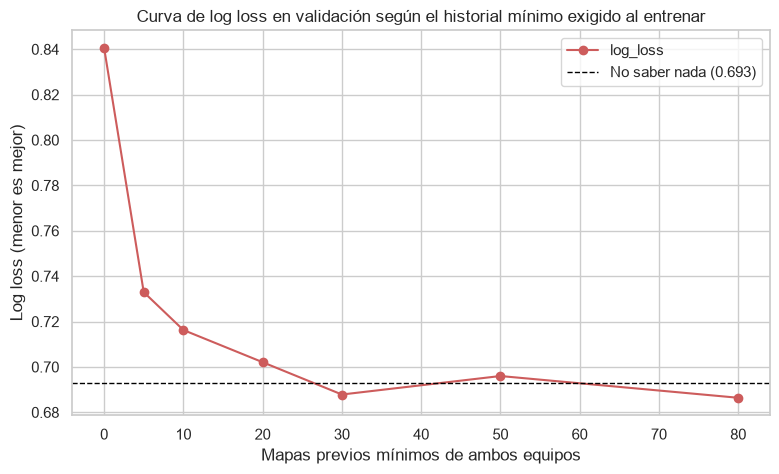

,train_maps,accuracy,roc_auc,log_loss
min_maps_played >=,,,,
0,25210,0.5668,0.5899,0.8406
5,11911,0.5676,0.5919,0.7329
10,9276,0.5637,0.5923,0.7163
20,6481,0.5629,0.5904,0.7021
30,5106,0.5723,0.5986,0.6878
50,3451,0.5597,0.5831,0.6960
80,1959,0.5668,0.5953,0.6864


In [6]:
rows = []
for threshold in [0, 5, 10, 20, 30, 50, 80]:
    subset = train[train["min_maps_played"] >= threshold]
    model = make_logistic().fit(subset[FEATURES], subset[TARGET])
    rows.append({"min_maps_played >=": threshold, "train_maps": len(subset),
                 **evaluate(y_val, model.predict_proba(X_val)[:, 1])})
sensitivity = pd.DataFrame(rows).set_index("min_maps_played >=")
sensitivity.to_csv(TABLES_DIR / "05_sensibilidad_umbral_historial.csv")

ax = sensitivity["log_loss"].plot(marker="o", color="indianred")
ax.axhline(0.693, color="black", linestyle="--", linewidth=1, label="No saber nada (0.693)")
ax.set(title="Curva de log loss en validación según el historial mínimo exigido al entrenar",
       xlabel="Mapas previos mínimos de ambos equipos", ylabel="Log loss (menor es mejor)")
ax.legend()
save_fig("05_curva_log_loss_historial")
plt.show()
sensitivity.round(4)

**Por qué este gráfico:** es la **curva de log loss** que justifica una de las decisiones más importantes del proyecto: con qué mapas se entrena. Se usa una línea porque interesa la *tendencia* del log loss a medida que se exige más historial.

**Cómo se lee:** en el eje horizontal está el historial mínimo exigido a ambos equipos para que un mapa entre al entrenamiento (0 = se usan todos). En el eje vertical, el log loss del modelo resultante medido en validación: **cuanto más abajo, mejor**. La línea punteada (0.693) es el log loss de responder siempre "50 %": un punto por encima de ella es un modelo peor que no saber nada.

**Qué muestra:** con todos los mapas (umbral 0) el log loss es 0.84, muy por encima de la referencia. Baja de forma sostenida al exigir más historial y cruza la línea de 0.693 alrededor de 30 mapas; a partir de ahí oscila sin mejorar, mientras el conjunto de entrenamiento sigue encogiéndose (columna `train_maps`). La exactitud y el AUC apenas cambian: lo que mejora es la calidad de las probabilidades.

**Decisión:** entrenar solo con mapas donde ambos equipos tienen al menos **30 mapas previos**.
Es el punto donde el problema desaparece sin sacrificar más datos de los necesarios, y
coincide con el tipo de partido que se quiere predecir (el 85 % de la validación cumple esa
condición, frente al 20 % del entrenamiento). El umbral se guarda en `config.yaml` para que
los cuadernillos 06, 07 y 08 usen el mismo.

In [7]:
MIN_HISTORY = 30
config["min_train_history"] = MIN_HISTORY
CONFIG_PATH.write_text(yaml.safe_dump(config, sort_keys=False, allow_unicode=True), encoding="utf-8")

train_fit = train[train["min_maps_played"] >= MIN_HISTORY]
X_train, y_train = train_fit[FEATURES], train_fit[TARGET]
print(f"Mapas de entrenamiento: {len(train)} → {len(train_fit)}")
train_fit["year"].value_counts().sort_index().to_frame("maps").T

Mapas de entrenamiento: 25210 → 5106


year,2021,2022,2023,2024
maps,1608,2017,585,896


## 4. El modelo: regresión logística

**Por qué se prueba:** es el modelo más simple para clasificación binaria y el punto de
partida natural. Supone que cada variable empuja la probabilidad en una dirección fija
(más ventaja de winrate → más probabilidad de ganar), que es justo lo que se observó en el
cuadernillo 02. Sus ventajas aquí: es **interpretable** (cada coeficiente dice cuánto pesa una
variable) y, con pocos parámetros, es difícil que se sobreajuste a unos miles de mapas.

**Límite:** no capta interacciones (por ejemplo, que el winrate importe más cuando hay mucho
historial) ni relaciones no lineales.

In [8]:
model = make_logistic().fit(X_train, y_train)
metrics = evaluate(y_val, model.predict_proba(X_val)[:, 1])

low, high = accuracy_interval(metrics["accuracy"], len(val))
print(f"Exactitud en validación: {metrics['accuracy']:.3f}  (IC 95 %: {low:.3f} – {high:.3f})")
pd.DataFrame({"Regresión logística": metrics}).T.to_csv(TABLES_DIR / "05_resultados_regresion_logistica.csv")
pd.Series(metrics).round(4)

Exactitud en validación: 0.572  (IC 95 %: 0.545 – 0.600)


accuracy    0.5723
roc_auc     0.5986
log_loss    0.6878
dtype: float64

El log loss baja de 0.84 a 0.688, por debajo de la referencia de 0.693. El intervalo de
confianza recuerda que la exactitud medida con 1 272 mapas tiene un margen de unos ±2.7 puntos.

### ¿Qué aprendió el modelo?

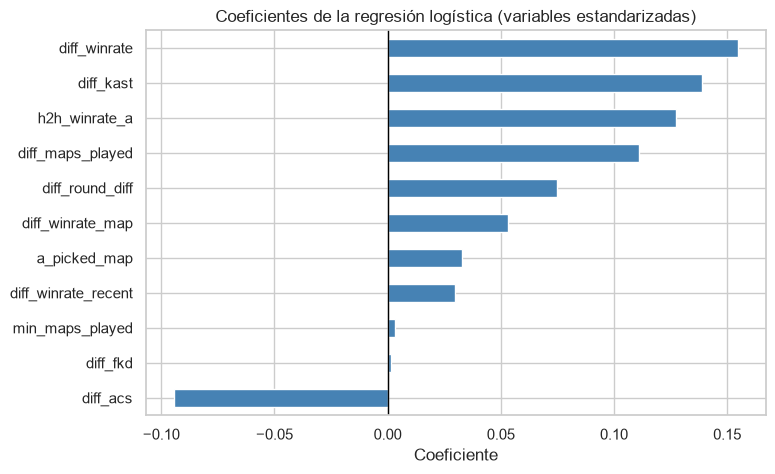

In [9]:
coefficients = pd.Series(model[-1].coef_[0], index=model[:-1].get_feature_names_out())
coefficients = coefficients[~coefficients.index.str.startswith("missingindicator")].sort_values()
ax = coefficients.plot.barh(color="steelblue", figsize=(8, 5))
ax.axvline(0, color="black", linewidth=1)
ax.set(title="Coeficientes de la regresión logística (variables estandarizadas)", xlabel="Coeficiente")
save_fig("05_coeficientes_logistica")
plt.show()

**Por qué este gráfico:** la ventaja de la regresión logística es que se puede "abrir": sus coeficientes dicen en qué dirección y con cuánta fuerza usa cada variable. Barras horizontales con una línea en 0 separan lo que empuja a favor y en contra.

**Cómo se lee:** cada barra es una variable. Una barra hacia la derecha (coeficiente positivo) significa que, cuando esa variable favorece a Team A, el modelo sube la probabilidad de que gane Team A; hacia la izquierda, que la baja. Cuanto más larga la barra, más pesa. Como las variables están estandarizadas, los largos se pueden comparar entre sí.

**Qué muestra:** los coeficientes son pequeños y están repartidos: winrate, KAST, enfrentamientos directos y experiencia empujan en el sentido esperado. `diff_acs` aparece con signo negativo, lo que **no** significa que tener mejor ACS perjudique: está muy correlacionada con `diff_round_diff` y `diff_kast` (cuadernillo 04) y, cuando varias variables cuentan lo mismo, la logística reparte el peso entre ellas de forma inestable. Por eso no conviene leer estos coeficientes uno por uno.

## Conclusiones

1. **Cómo se mide:** exactitud, ROC-AUC y log loss. El log loss es el criterio principal y su
   referencia es 0.693 (responder siempre 50 %).
2. **Problema encontrado:** entrenada con todos los mapas, la logística queda muy mal
   calibrada (log loss 0.84): reparte probabilidades extremas que no se cumplen. La causa es
   que el entrenamiento está dominado por los clasificatorios de 2021–2022, muy distintos de
   las ligas actuales.
3. **Solución:** entrenar solo con mapas donde ambos equipos tienen 30 o más mapas previos
   (5 106 de 25 210). La curva de log loss muestra que ese es el punto donde el modelo baja
   de la referencia de 0.693.
4. **Resultado de la regresión logística en validación (2025):** exactitud 0.572
   (IC 95 %: 0.545–0.600), ROC-AUC 0.599 y log loss 0.688.
5. **Qué aprendió:** pesos pequeños y repartidos entre winrate, KAST, enfrentamientos directos
   y experiencia; ninguna variable domina.

**Siguiente paso (cuadernillo 06):** probar un modelo que sí capta relaciones no lineales, el
Random Forest, con los mismos datos.